# 05 - Ensemble Learning

- **Random Forest** (obrigatório): bagging de árvores + seleção aleatória de features
  em cada divisão (Aula 07).
- **Gradient Boosting** (segundo método): árvores rasas treinadas em sequência, cada
  uma corrigindo os resíduos das anteriores.
- Hiperparâmetros ajustados com `GridSearchCV` (5 folds) somente no treino, com a mesma
  métrica do notebook 04 (F1 / RMSE).
- Curva do erro × número de árvores da Random Forest (viés e variância).
- Importância das features comparada às variáveis usadas nas regras do especialista.

In [1]:
import sys
sys.path.insert(0, "..")
import warnings
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import (GradientBoostingClassifier, GradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, validation_curve

from src.config import ARQUIVO_REGRAS, MODELS, SEED, carregar_split, salvar_fig, salvar_tabela
from src.expert_system import BaseConhecimento
from src.metrics import SCORING_CV

sns.set_style("whitegrid")
dados = {p: carregar_split(p) for p in ("classificacao", "regressao")}
cv = {"classificacao": StratifiedKFold(5, shuffle=True, random_state=SEED),
      "regressao": KFold(5, shuffle=True, random_state=SEED)}

## 1. Ajuste de hiperparâmetros

In [2]:
grades = {
    ("rf", "classificacao"): (RandomForestClassifier(random_state=SEED), {
        "n_estimators": [100, 300],
        "max_depth": [8, 12, None],
        "max_features": ["sqrt", 0.5],
        "min_samples_leaf": [1, 5],
        "class_weight": [None, "balanced"],
    }),
    ("rf", "regressao"): (RandomForestRegressor(random_state=SEED), {
        "n_estimators": [100, 300],
        "max_depth": [6, 8, 12, None],
        "max_features": ["sqrt", 0.5],
        "min_samples_leaf": [1, 5, 10],
    }),
    ("gb", "classificacao"): (GradientBoostingClassifier(random_state=SEED), {
        "n_estimators": [100, 300],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
    }),
    ("gb", "regressao"): (GradientBoostingRegressor(random_state=SEED), {
        "n_estimators": [100, 300, 600],
        "learning_rate": [0.01, 0.03, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
    }),
}

buscas = {}
for (sigla, problema), (modelo, grade) in grades.items():
    X_train, X_test, y_train, y_test = dados[problema]
    busca = GridSearchCV(modelo, grade, scoring=SCORING_CV[problema], cv=cv[problema],
                         n_jobs=-1, return_train_score=True)
    busca.fit(X_train, y_train)
    buscas[(sigla, problema)] = busca
    joblib.dump(busca.best_estimator_, MODELS / f"{sigla}_{problema}.joblib")
    salvar_tabela(pd.DataFrame(busca.cv_results_).drop(columns="params"),
                  f"{sigla}_gridsearch_{problema}", index=False)
    print(f"{sigla.upper()} {problema}: {busca.best_params_} | CV = {abs(busca.best_score_):.4f}")

RF classificacao: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 300} | CV = 0.8044


RF regressao: {'max_depth': 8, 'max_features': 0.5, 'min_samples_leaf': 5, 'n_estimators': 300} | CV = 11.9522


GB classificacao: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0} | CV = 0.8191


GB regressao: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 0.8} | CV = 11.8515


In [3]:
melhores = pd.DataFrame([{"modelo": s.upper(), "problema": p, "cv_media": abs(b.best_score_),
                          "cv_desvio": b.cv_results_["std_test_score"][b.best_index_],
                          "parametros": b.best_params_} for (s, p), b in buscas.items()])
salvar_tabela(melhores, "ensemble_melhores_parametros", index=False)
melhores

,modelo,problema,cv_media,cv_desvio,parametros
0,RF,classificacao,0.804356,0.014596,"{'class_weight': 'balanced', 'max_depth': None..."
1,RF,regressao,11.952246,0.168977,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."
2,GB,classificacao,0.819144,0.016408,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti..."
3,GB,regressao,11.851546,0.193577,"{'learning_rate': 0.03, 'max_depth': 2, 'n_est..."


## 2. Random Forest: erro × número de árvores

`validation_curve` (5 folds, só treino) variando `n_estimators` com os demais
hiperparâmetros fixos nos melhores valores. Erro = 1 − F1 (classificação) e RMSE
(regressão).

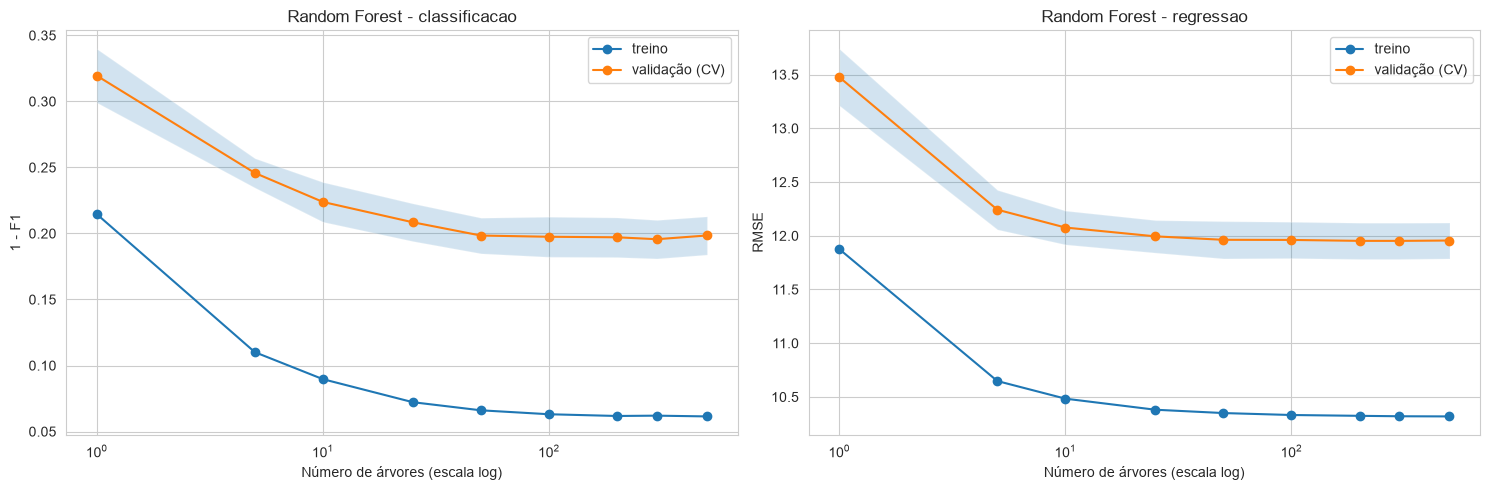

,problema,n_arvores,erro_treino,erro_cv,erro_cv_desvio
0,classificacao,1,0.2146,0.3195,0.0204
1,classificacao,5,0.1101,0.2458,0.0111
2,classificacao,10,0.0897,0.2239,0.0150
3,classificacao,25,0.0722,0.2085,0.0143
4,classificacao,50,0.0661,0.1984,0.0135
5,classificacao,100,0.0631,0.1975,0.0152
6,classificacao,200,0.0618,0.1971,0.0150
7,classificacao,300,0.0620,0.1956,0.0146
8,classificacao,500,0.0614,0.1985,0.0145
0,regressao,1,11.8754,13.4757,0.2638


In [4]:
n_arvores = [1, 5, 10, 25, 50, 100, 200, 300, 500]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
curvas = []
for ax, problema in zip(axes, ("classificacao", "regressao")):
    X_train, _, y_train, _ = dados[problema]
    modelo = clone(buscas[("rf", problema)].best_estimator_)
    tr, va = validation_curve(modelo, X_train, y_train, param_name="n_estimators",
                              param_range=n_arvores, scoring=SCORING_CV[problema],
                              cv=cv[problema], n_jobs=-1)
    erro = (lambda s: 1 - s) if problema == "classificacao" else (lambda s: -s)
    tr, va = erro(tr), erro(va)
    ax.plot(n_arvores, tr.mean(1), "o-", label="treino")
    ax.plot(n_arvores, va.mean(1), "o-", label="validação (CV)")
    ax.fill_between(n_arvores, va.mean(1) - va.std(1), va.mean(1) + va.std(1), alpha=0.2)
    ax.set_xscale("log")
    ax.set_xlabel("Número de árvores (escala log)")
    ax.set_ylabel("1 - F1" if problema == "classificacao" else "RMSE")
    ax.set_title(f"Random Forest - {problema}")
    ax.legend()
    curvas.append(pd.DataFrame({"problema": problema, "n_arvores": n_arvores,
                                "erro_treino": tr.mean(1), "erro_cv": va.mean(1),
                                "erro_cv_desvio": va.std(1)}))
plt.tight_layout()
salvar_fig("rf_curva_n_arvores")
plt.show()
curvas = pd.concat(curvas)
salvar_tabela(curvas, "rf_curva_n_arvores", index=False)
curvas.round(4)

**Leitura (viés × variância):** com 1 árvore o erro de validação é o maior da curva:
uma árvore isolada, treinada em uma amostra bootstrap, tem **alta variância**. À medida
que árvores pouco correlacionadas são somadas, a variância da média cai e o erro de
validação diminui rapidamente, estabilizando a partir de ~50 árvores. O que sobra é o
**viés** (e o ruído irredutível), que a média não reduz; por isso a curva vira um platô.
A distância constante entre treino e validação mostra que mais árvores **não** causam
overfitting: a partir do platô só aumentam o custo de treino, inferência e disco.

## 3. Importância das features × variáveis das regras do especialista

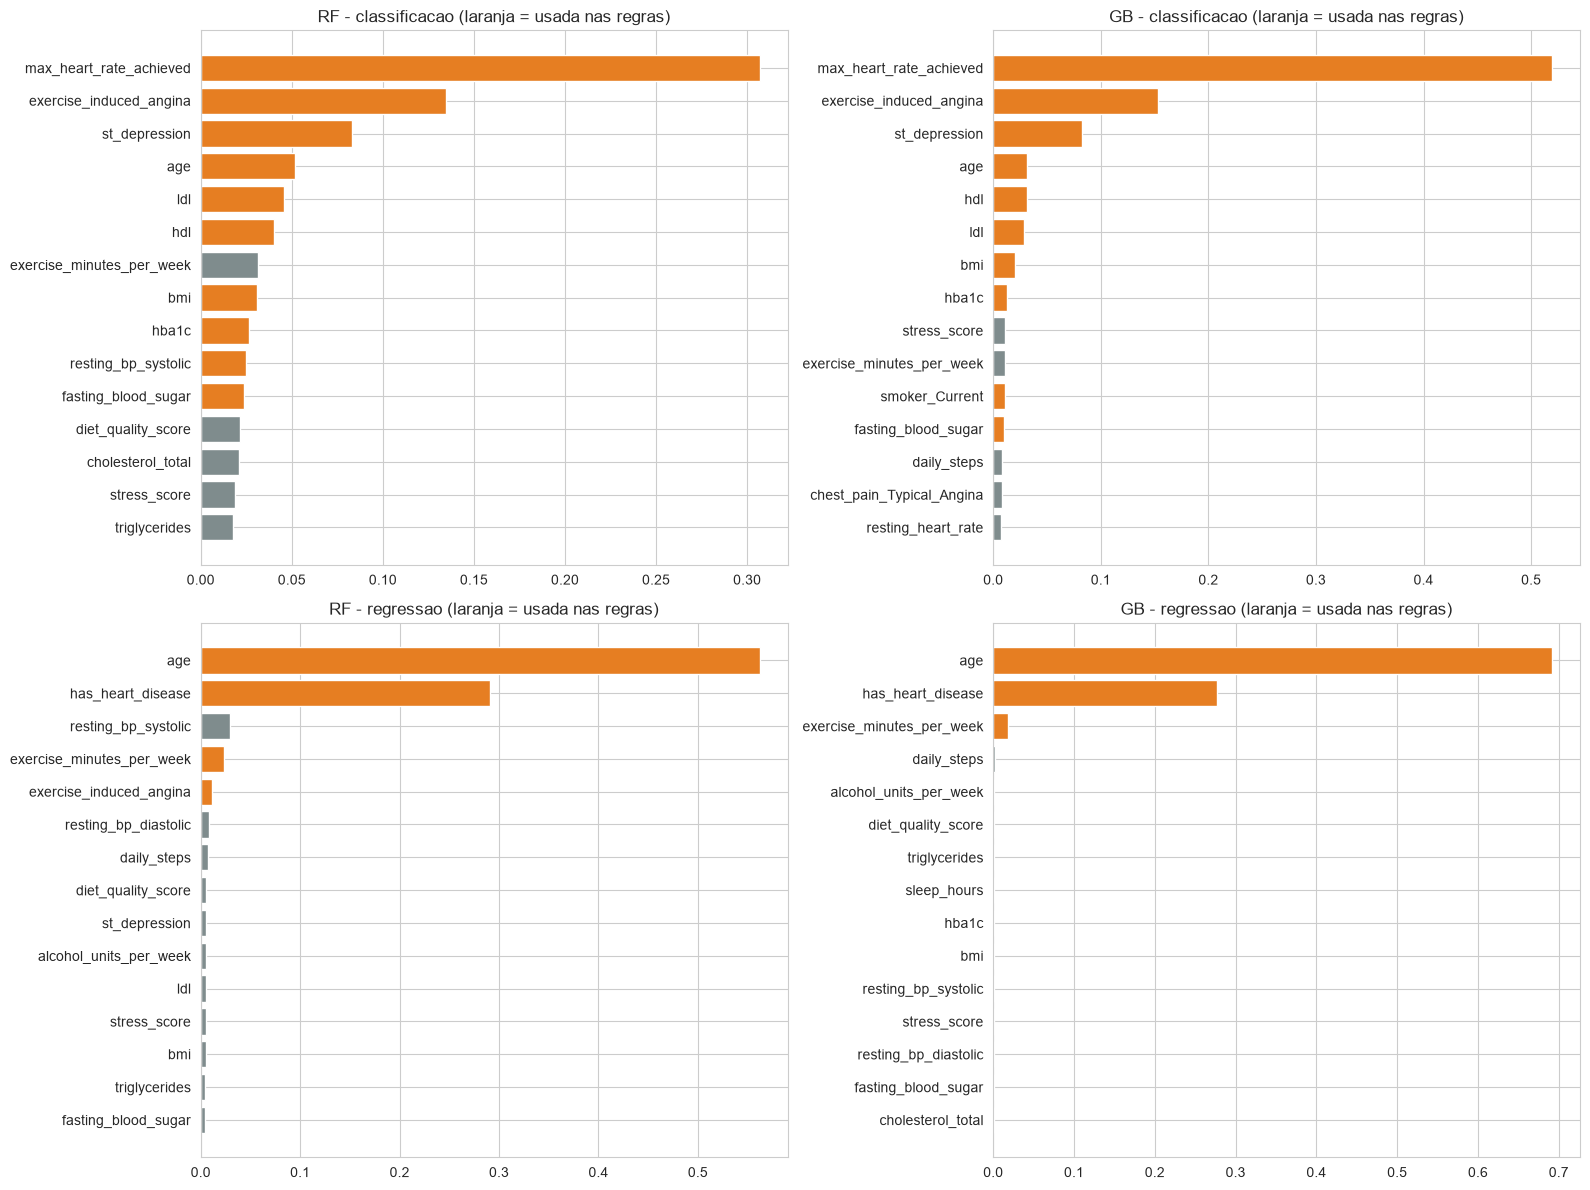


classificacao: variáveis das regras -> rank na RF:
                feature  rank  importancia
max_heart_rate_achieved     1     0.306819
exercise_induced_angina     2     0.134735
          st_depression     3     0.083273
                    age     4     0.051694
                    ldl     5     0.045636
                    hdl     6     0.040308
                    bmi     8     0.030748
                  hba1c     9     0.026367
    resting_bp_systolic    10     0.025074
    fasting_blood_sugar    11     0.023941
         smoker_Current    21     0.008119
         family_history    26     0.003022

regressao: variáveis das regras -> rank na RF:
                  feature  rank  importancia
                      age     1     0.562010
        has_heart_disease     2     0.290830
exercise_minutes_per_week     4     0.023694
  exercise_induced_angina     5     0.011069


In [5]:
usadas = {p: set(BaseConhecimento.de_arquivo(ARQUIVO_REGRAS[p]).variaveis_usadas())
          for p in ARQUIVO_REGRAS}
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
tabelas = []
for i, problema in enumerate(("classificacao", "regressao")):
    X_train = dados[problema][0]
    for j, sigla in enumerate(("rf", "gb")):
        imp = pd.Series(buscas[(sigla, problema)].best_estimator_.feature_importances_,
                        index=X_train.columns).sort_values(ascending=False)
        top = imp.head(15)[::-1]
        cores = ["#e67e22" if f in usadas[problema] else "#7f8c8d" for f in top.index]
        axes[i, j].barh(top.index, top.values, color=cores)
        axes[i, j].set_title(f"{sigla.upper()} - {problema} (laranja = usada nas regras)")
        tabelas.append(pd.DataFrame({"problema": problema, "modelo": sigla.upper(),
                                     "feature": imp.index, "importancia": imp.values,
                                     "rank": range(1, len(imp) + 1),
                                     "usada_nas_regras": [f in usadas[problema] for f in imp.index]}))
plt.tight_layout()
salvar_fig("ensemble_importancia_features")
plt.show()
importancias = pd.concat(tabelas)
salvar_tabela(importancias, "ensemble_importancia_features", index=False)

for problema in ("classificacao", "regressao"):
    rf = importancias.query("problema == @problema and modelo == 'RF'")
    print(f"\n{problema}: variáveis das regras -> rank na RF:")
    print(rf[rf["usada_nas_regras"]][["feature", "rank", "importancia"]].to_string(index=False))